# Feature Importance Analyses for Mislocalized Variants

We select for the interpretable CellProfiler features that contribute most significantly in the XGBoost Classifier to help distinguish the mislocalized variants from their respective reference alleles.

In [182]:
import os
import random
import operator
from tqdm import tqdm
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from functools import reduce
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
import umap

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }
# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

np.random.seed(42)
random.seed(42)

## 1. Load feature importance and classifier info

In [170]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

### 1.1 Feature importance for each variant

In [171]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
print("Number of hits:", imaging_summary_clinvar_hits.shape[0])
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())
hits_allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())

Number of hits: 223


### 1.2 Select for the CP features with importance > 1e-3 for each variant

In [5]:
# feat_import_df_feat = pl.DataFrame()
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         # Read the data
#         feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
#         meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
#         feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
#         feat_df_batch = feat_df.with_columns(
#             [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
#         ).with_columns(
#             pl.lit(batch_id).alias("Metadata_Batch"),
#             pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
#        ).filter(
#             (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
#             &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(batch_allele_list)))
#         ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
#         feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch.collect()], how="diagonal")

In [6]:
# key_alleles_df = imaging_summary_clinvar.to_pandas()
# feat_df = pl.DataFrame()
# importance_thres = 1e-3
# # top_num = 5

# for j, allele in tqdm(key_alleles_df.iterrows()):
#     batch_list = list(feat_import_df_feat.filter(
#         pl.col("Metadata_gene_allele")==allele["gene_allele"]
#     ).unique("Metadata_Batch")["Metadata_Batch"])
#     allele_df = pl.DataFrame()
#     for i, batch in enumerate(batch_list):
#         batch_df = feat_import_df_feat.filter(
#             (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
#         )
#         feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
#         batch_df = batch_df.filter(
#             ~pl.all_horizontal(pl.col(feat_cols).is_null())
#         )
#         non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
#         batch_df_col = (
#             batch_df.select(non_null_gfp).mean()
#            .transpose(include_header=True)
#            .filter(pl.col("column_0") > importance_thres)
#            .sort("column_0", descending=True)
#            # .head(top_num)#["column"]
#            # .to_list()
#         )
#         if not allele_df.is_empty():
#             allele_df = allele_df.join(
#                 batch_df_col.with_columns(
#                     pl.col("column_0").alias(batch),
#                     pl.col("column").alias("index"),
#                 ).select("index", batch),
#                 on="index",
#                 how="full",
#                 coalesce=True
#             )
#         else:
#             allele_df = batch_df_col.with_columns(
#                 pl.col("column_0").alias(batch),
#                 pl.col("column").alias("index"),
#             ).select("index", batch)
            
#     allele_df = allele_df.with_columns(
#         pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
#         pl.col("index").alias("cp_feature")
#     ).select(
#         pl.col(["cp_feature", "feat_importance"])
#     ).rename(
#         {"feat_importance": allele["gene_allele"]}
#     )
#     if not feat_df.is_empty():
#         feat_df = feat_df.join(
#             allele_df,
#             left_on="cp_feature",
#             right_on="cp_feature",
#             how="full",
#             coalesce=True
#         )
#     else:
#         feat_df = allele_df

915it [02:45,  5.54it/s]


In [8]:
# feat_df.write_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

### 1.3 Load CellProfiler features

#### 1.3.1 Loading some QC

In [172]:
# feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")
# feat_df.shape

#### 1.3.2 Load the features from the valid cells only

In [59]:
# # Paths
# ref_var_cell_qc_prof_df = pl.DataFrame()
# target_gene_alleles = []
# meta_cols = [
#     "Metadata_CellID",
#     "Metadata_gene_allele",
#     "Metadata_Well",
#     "Metadata_Plate",
#     "Metadata_node_type"
# ]

# # Get meta features
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 PASS_QC_PROF_PQ.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         ).collect()
#         # feat_cols = [col for col in batch_alleles.columns if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) and ("GFP".lower() not in col.lower())]
#         batch_alleles = batch_alleles.join(
#             img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
#             left_on=["Metadata_Plate", "Metadata_Well"],
#             right_on=["plate", "well"]
#         ).filter(
#             ~pl.col("is_bg")
#         ).select(pl.col(meta_cols))
#         ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

#### 1.3.3 Load all the features available

In [62]:
# # Paths
# ref_var_cell_all_prof_list = []
# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 ALL_PROF_QC.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         )
#         ref_var_cell_all_prof_list.append(batch_alleles)

# # all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if (FEAT.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
# # select_cols = list(all_feat_cols) + ["Metadata_CellID"]
# # ref_var_cell_all_prof_df = pl.concat([batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list])

# select_cols = ["Metadata_CellID"] + list(feat_df["cp_feature"])
# ref_var_cell_all_prof_df = pl.concat(
#     [batch_alleles.select([c for c in select_cols if c in batch_alleles.collect_schema()]).collect() for batch_alleles in ref_var_cell_all_prof_list],
#     how="diagonal"
# )
# # This method of joining ensures that only cells past filters are included in the abundance analysis
# ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
#                                                         on="Metadata_CellID", 
#                                                         how="left", coalesce=True)
# # ref_var_cell_all_prof_df.write_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_sig_feat_sc_cp_profiles.parquet")

## 2. Overall Variant Analyses

In [167]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_sig_feat_sc_cp_profiles.parquet")
ref_var_cell_all_prof_df.shape

(2786986, 272)

### 2.1 Feature normalization by z-score

Calculate the mean and std of each feature across all the single-cell data from every gene, and normalize the variant-level single-cell aggregated feature to a Z-score by subtract the reference-gene mean and divided by reference-gene std.

In [174]:
norm_vars_feat_df = pl.DataFrame()
sig_diff_feat = list(feat_df["cp_feature"])

for gene in tqdm(imaging_summary_clinvar["Gene"].unique()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()
    var_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.contains(gene))&(pl.col("Metadata_gene_allele")!=gene)
    ).group_by(
        "Metadata_gene_allele"
    ).agg(
        pl.col(col).median().alias(col)
        for col in ref_var_cell_all_prof_df.columns
        if not col.startswith("Metadata_")
    ).to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]
    norm_gene_var_feat_df = (var_feat_df - gene_mean) / gene_std
    norm_vars_feat_df = pl.concat([norm_vars_feat_df, pl.DataFrame(norm_gene_var_feat_df.reset_index())], how="diagonal")

100%|██████████| 131/131 [00:21<00:00,  6.05it/s]


In [175]:
norm_vars_feat_df.shape

(917, 268)

### 2.2 Feature cleaning by removing low-variance and corr. features

In [178]:
## remove corr features
norm_vars_feat_select_df = feature_select(norm_vars_feat_df.to_pandas(), operation="variance_threshold")
norm_vars_feat_select_df = feature_select(norm_vars_feat_select_df, operation="correlation_threshold")
norm_vars_feat_select_df.shape

(917, 83)

In [180]:
norm_vars_hits_feat_df = norm_vars_feat_df.filter(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_allele"]))
## remove corr features
norm_vars_hits_feat_sel_df = feature_select(norm_vars_hits_feat_df.to_pandas(), operation="variance_threshold")
norm_vars_hits_feat_sel_df = feature_select(norm_vars_hits_feat_sel_df, operation="correlation_threshold")
norm_vars_hits_feat_sel_df.shape

(223, 66)

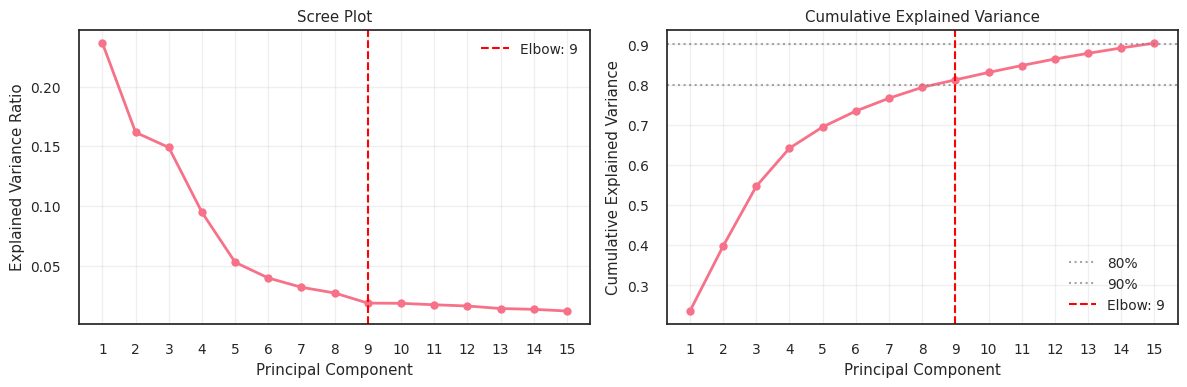

Optimal components: 9
Explained variance at elbow: 81.2%


In [279]:
# Standardize by column
scaler = StandardScaler()
data_scaled = scaler.fit_transform(norm_vars_hits_feat_sel_df.iloc[:,1:].fillna(0))

# Fit PCA with all components
pca_full = PCA()
pca_full.fit(data_scaled)

# Calculate variances
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

from kneed import KneeLocator
# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee

# explained_var_thres = 0.6
# cumvar = np.cumsum(pca_full.explained_variance_ratio_)
# optimal_components = np.argmax(cumvar >= explained_var_thres) + 1

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

# Apply optimal PCA
pca = PCA(n_components=optimal_components)
data_pca = pca.fit_transform(data_scaled)

In [280]:
# Generate k-NN graph
k = 15  # adjust based on testing
nbrs = NearestNeighbors(n_neighbors=k, metric='cosine')
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# Build unweighted graph
G = nx.Graph()
for i in range(len(data_pca)):
    for j in indices[i][1:]:  # skip self
        G.add_edge(i, j)

# Louvain clustering
cluster_dict = community_louvain.best_partition(G, resolution=1.5)

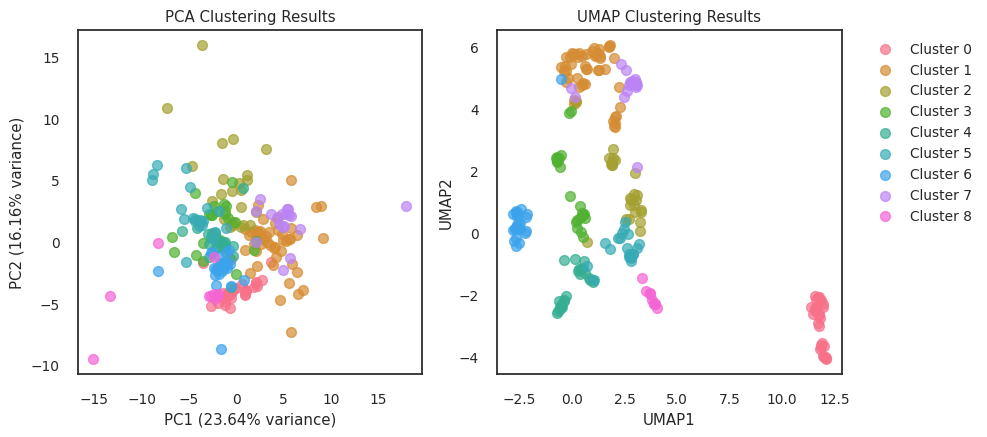

In [282]:
# Convert dictionary to list in correct order
clusters = [cluster_dict[i] for i in range(len(data_pca))]

# Get unique clusters and create color palette
unique_clusters = np.unique(clusters)
n_clusters = len(unique_clusters)
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(unique_clusters)}

fig, ax = plt.subplots(1,2, figsize=(10, 4.5))

# PCA plot
for cluster in unique_clusters:
    mask = np.array(clusters) == cluster
    ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
                 c=[color_map[cluster]], label=f'Cluster {cluster}',
                 s=50, alpha=0.7)

ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
# ax[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# UMAP plot
reducer = umap.UMAP(n_components=2, metric='cosine', random_state=42)
embedding = reducer.fit_transform(data_pca)

for cluster in unique_clusters:
    mask = np.array(clusters) == cluster
    ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
                 c=[color_map[cluster]], label=f'Cluster {cluster}',
                 s=50, alpha=0.7)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')
ax[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

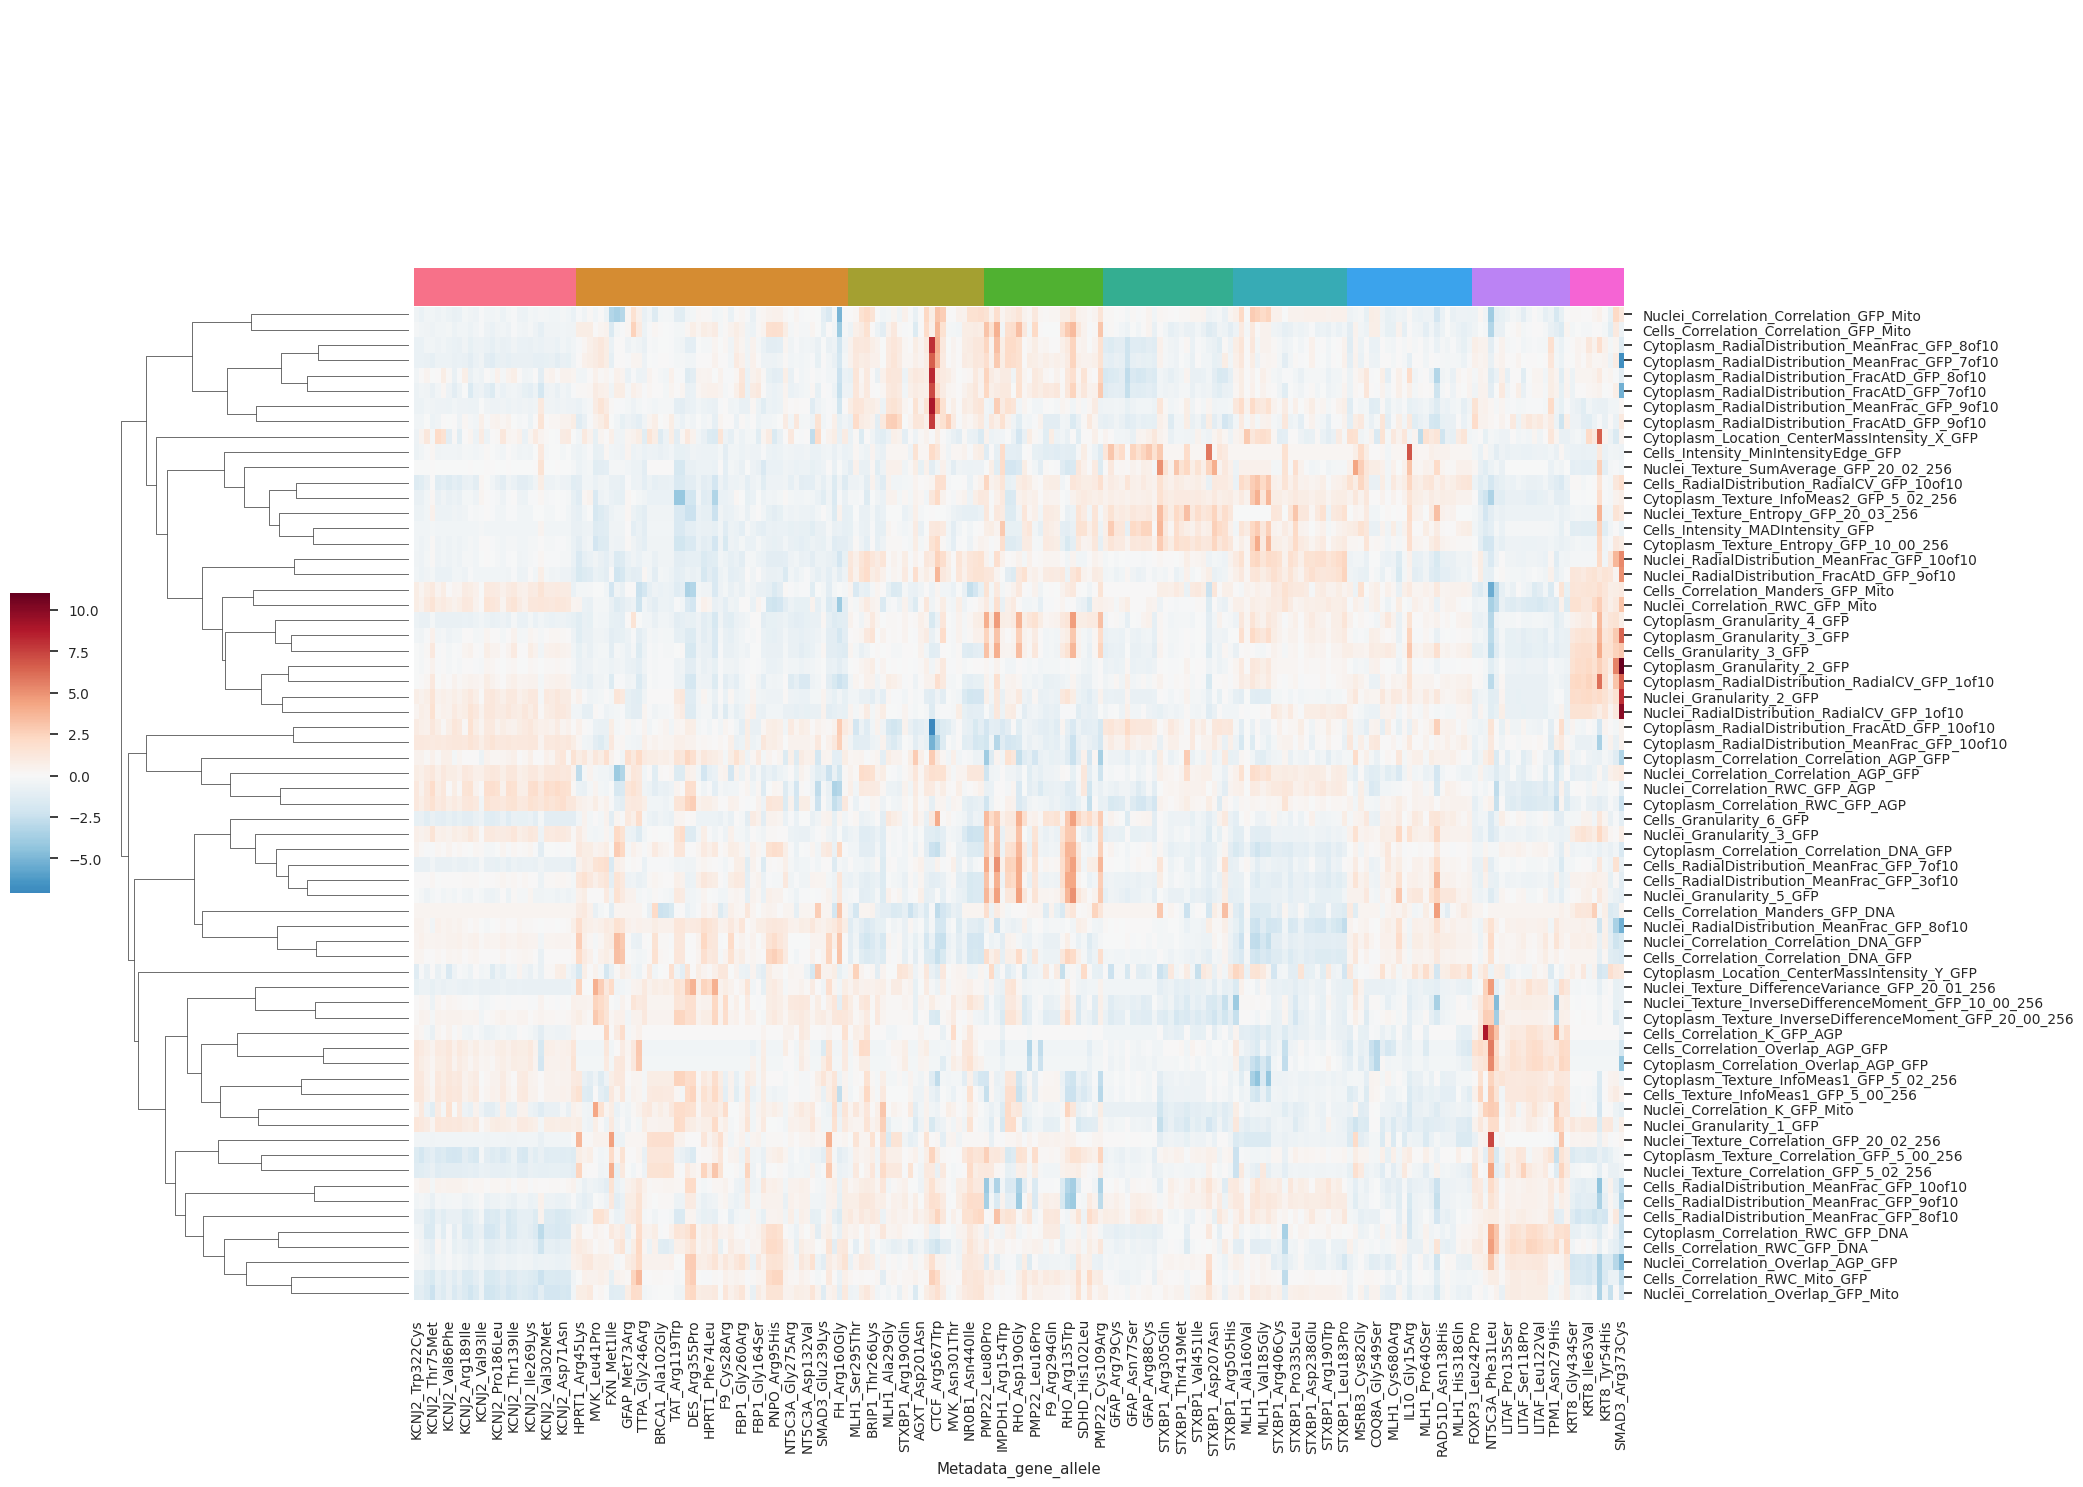

In [317]:
# Create dataframe with cluster labels
data_scaled_df = pd.DataFrame(data_scaled, 
                              index=norm_vars_hits_feat_sel_df["Metadata_gene_allele"], 
                              columns=norm_vars_hits_feat_sel_df.columns[1:])

df_clustered = data_scaled_df.copy()
df_clustered['cluster'] = [clusters[i] for i in range(len(df_clustered))]

# Sort by cluster for better visualization
df_sorted = df_clustered.sort_values('cluster')
cluster_labels = df_sorted['cluster'].values
# Create cluster colormap
cluster_colors = color_map #sns.color_palette("tab10", len(set(cluster_labels)))

data_for_heatmap = df_sorted.drop('cluster', axis=1)
row_colors = [cluster_colors[c] for c in cluster_labels]

sns.clustermap(data_for_heatmap.T, 
               row_cluster=True, 
               col_cluster=False,
               col_colors=row_colors,
               cbar_pos=(-0.04, 0.4, 0.02, 0.2),
               cmap='RdBu_r', 
               center=0,
               yticklabels=1,
               figsize=(20, 15))
plt.show()

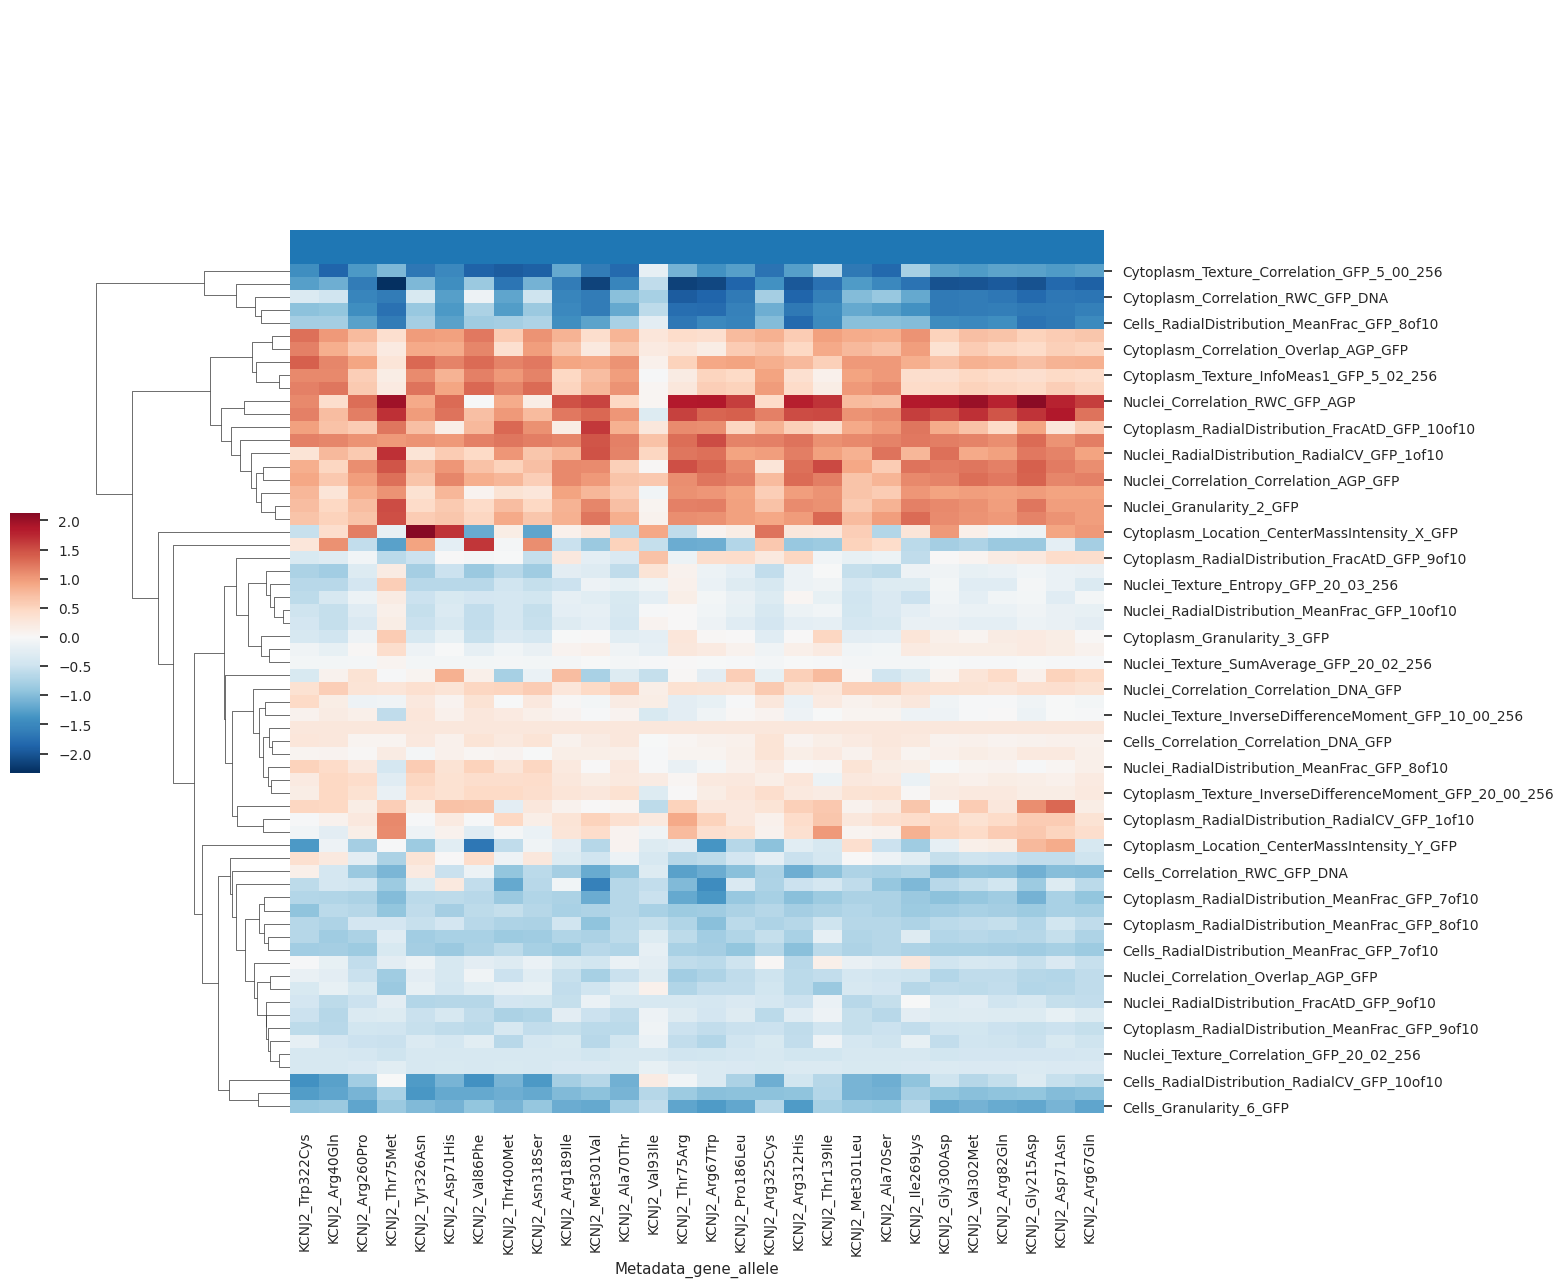

In [290]:
cluster_labels_kcnj2 = df_sorted.loc[[var for var in data_for_heatmap.index if "KCNJ2" in var],:]['cluster'].values
data_for_heatmap_kcnj2 = df_sorted.loc[[var for var in data_for_heatmap.index if "KCNJ2" in var],:].drop('cluster', axis=1)
row_colors_kcnj2 = [cluster_colors[c] for c in cluster_labels_kcnj2]

sns.clustermap(data_for_heatmap_kcnj2.T, 
               row_cluster=True, 
               col_cluster=False,
               col_colors=row_colors_kcnj2,
               cbar_pos=(-0.04, 0.4, 0.02, 0.2),
               cmap='RdBu_r', center=0,
               figsize=(15, 13))
plt.show()

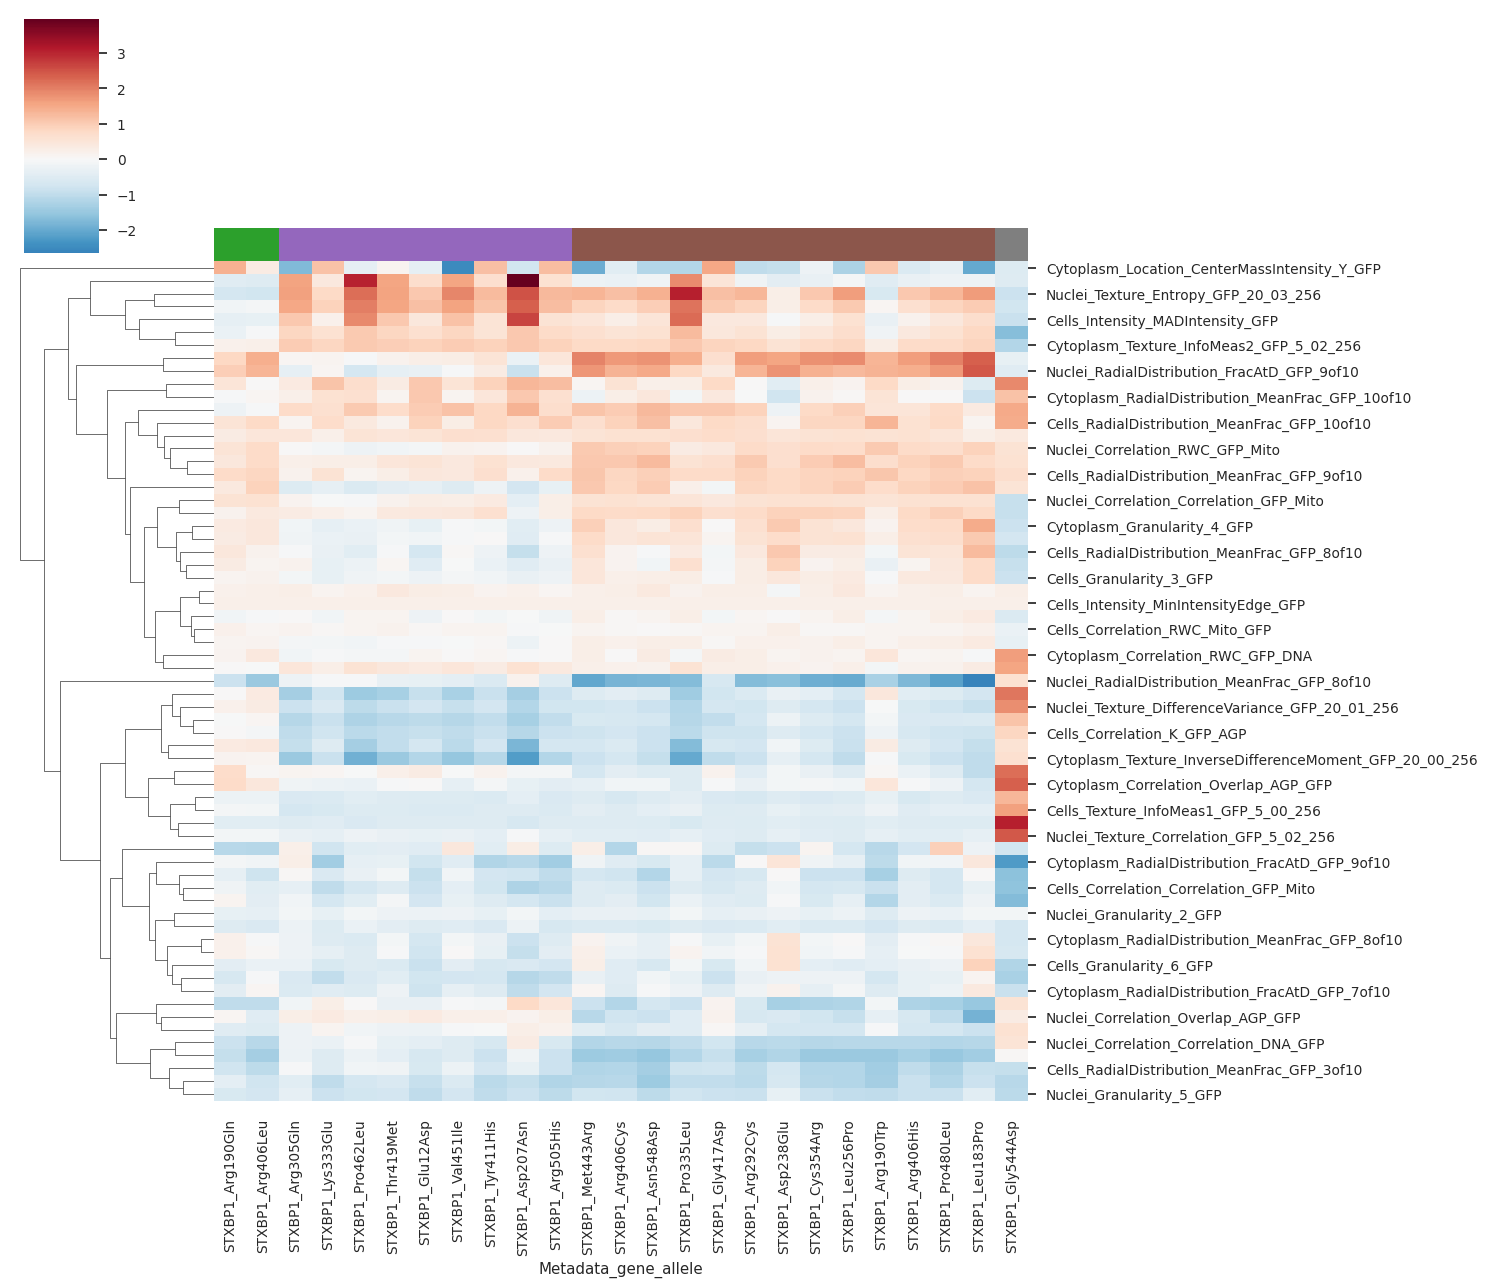

In [291]:
cluster_labels_stx = df_sorted.loc[[var for var in data_for_heatmap.index if "STXBP1" in var],:]['cluster'].values
data_for_heatmap_stx = df_sorted.loc[[var for var in data_for_heatmap.index if "STXBP1" in var],:].drop('cluster', axis=1)
row_colors_stx = [cluster_colors[c] for c in cluster_labels_stx]

sns.clustermap(data_for_heatmap_stx.T, 
               # z_score=0,
               row_cluster=True, col_cluster=False,
               col_colors=row_colors_stx,
               cmap='RdBu_r', center=0,
               figsize=(15, 13))
plt.show()

In [292]:
map_clus_df = pl.DataFrame(df_clustered.reset_index()).join(
    imaging_summary_clinvar_hits,
    left_on="Metadata_gene_allele",
    right_on="gene_allele"
)

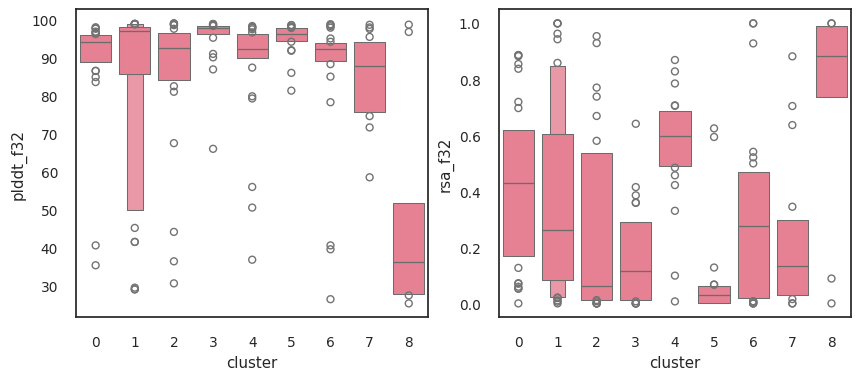

In [294]:
fig, ax = plt.subplots(1,2,figsize=(10,4))
sns.boxenplot(
    data=map_clus_df.to_pandas(),
    x="cluster",
    y="plddt_f32",
    ax=ax[0]
)
sns.boxenplot(
    data=map_clus_df.to_pandas(),
    x="cluster",
    y="rsa_f32",
    ax=ax[1]
)
plt.show()

In [297]:
from scipy.stats import ks_2samp
from statsmodels.stats.multitest import multipletests

def analyze_cluster_features(data_original, clusters, feature_names=None, 
                             significance_threshold=0.001, top_n=0, 
                             sort_by='effect_size'):
    """
    Identify differential features for each cluster using KS-test
    
    Parameters:
    -----------
    data_original: samples x features (rows=samples, columns=features)
    clusters: dict {sample_index: cluster_id}
    significance_threshold: p-value threshold after Bonferroni correction
    top_n: int, number of top features to return. If 0, return all significant features
    sort_by: str, sorting method {'effect_size', 'p_value', 'combined'}
        - 'effect_size': sort by absolute effect size (largest first)
        - 'p_value': sort by corrected p-value (smallest first)  
        - 'combined': sort by significance first, then effect size
    """
    # Convert to numpy array if DataFrame
    if isinstance(data_original, pd.DataFrame):
        data_array = data_original.values
        if feature_names is None:
            feature_names = data_original.columns.tolist()
    else:
        data_array = data_original
        if feature_names is None:
            feature_names = [f'Feature_{i}' for i in range(data_array.shape[1])]
    
    results = {}
    
    for cluster_id in set(clusters.values()):
        # Get sample indices for this cluster vs others
        cluster_sample_indices = [i for i, c in clusters.items() if c == cluster_id]
        other_sample_indices = [i for i, c in clusters.items() if c != cluster_id]
        
        # Extract data for samples in this cluster vs others
        cluster_data = data_array[cluster_sample_indices, :]
        other_data = data_array[other_sample_indices, :]
        
        # Perform KS-test for each feature
        p_values = []
        statistics = []
        
        for feature_idx in range(data_array.shape[1]):
            cluster_feature_values = cluster_data[:, feature_idx]
            other_feature_values = other_data[:, feature_idx]
            
            stat, p_val = ks_2samp(cluster_feature_values, other_feature_values)
            p_values.append(p_val)
            statistics.append(stat)
        
        # Bonferroni correction
        rejected, p_corrected, _, _ = multipletests(p_values, method='bonferroni')
        
        # Calculate effect size (difference in medians)
        effect_sizes = []
        for feature_idx in range(data_array.shape[1]):
            cluster_median = np.median(cluster_data[:, feature_idx])
            other_median = np.median(other_data[:, feature_idx])
            effect_sizes.append(cluster_median - other_median)
        
        # Create results dataframe for this cluster
        cluster_results = pd.DataFrame({
            'feature': feature_names,
            'ks_statistic': statistics,
            'p_value': p_values,
            'p_corrected': p_corrected,
            'significant': rejected,
            'effect_size': effect_sizes,
            'abs_effect_size': np.abs(effect_sizes)
        })
        
        # Apply filtering and sorting based on parameters
        if top_n == 0:
            # Return all significant features
            filtered_results = cluster_results[cluster_results['p_corrected'] < significance_threshold]
        else:
            # Return top_n features regardless of significance
            filtered_results = cluster_results.copy()
        
        # Sort based on chosen method
        if sort_by == 'effect_size':
            filtered_results = filtered_results.sort_values('abs_effect_size', ascending=False)
        elif sort_by == 'p_value':
            filtered_results = filtered_results.sort_values('p_corrected', ascending=True)
        elif sort_by == 'combined':
            filtered_results = filtered_results.sort_values(
                ['significant', 'abs_effect_size'], 
                ascending=[False, False]
            )
        
        # Apply top_n limit if specified
        if top_n > 0:
            filtered_results = filtered_results.head(top_n)
        
        results[f'Cluster_{cluster_id}'] = filtered_results
    
    return results


def display_results(cluster_results, clusters):
    """Display results in formatted way"""
    for cluster_name, df in cluster_results.items():
        cluster_id = int(cluster_name.split('_')[1])
        n_samples = sum(1 for c in clusters.values() if c == cluster_id)
        n_features = len(df)
        n_significant = (df['p_corrected'] < 0.001).sum()
        
        print(f"\n{cluster_name} (n={n_samples}):")
        print(f"Features shown: {n_features} (significant: {n_significant})")
        
        if n_features > 0:
            for idx, row in df.iterrows():
                sig_marker = "***" if row['p_corrected'] < 0.001 else "**" if row['p_corrected'] < 0.01 else "*" if row['p_corrected'] < 0.05 else ""
                direction = "↑" if row['effect_size'] > 0 else "↓"
                print(f"  {row['feature']}: KS={row['ks_statistic']:.3f}, p_corr={row['p_corrected']:.2e} {sig_marker}, effect={row['effect_size']:.3f} {direction}")
        else:
            print("  No features found")

# # Usage examples:
# # 1. All significant features (p < 0.001), sorted by effect size
# results_all_sig = analyze_cluster_features(data_scaled, clusters, 
#                                            significance_threshold=0.001, 
#                                            top_n=0, 
#                                            sort_by='combined')
# print("=== ALL SIGNIFICANT FEATURES (p < 0.001) ===")
# display_results(results_all_sig, clusters)

# # 2. Top 3 features regardless of significance, sorted by p-value
# results_top3_pval = analyze_cluster_features(data_scaled, clusters, 
#                                             top_n=3, 
#                                             sort_by='p_value')
# print("\n\n=== TOP 3 FEATURES BY P-VALUE ===")
# display_results(results_top3_pval, clusters)

# 3. Top 5 features, sorted by combined significance + effect size
results_top5_combined = analyze_cluster_features(data_scaled, 
                                                 cluster_dict, 
                                                 top_n=10, 
                                                 sort_by='combined')
print("\n\n=== TOP 5 FEATURES BY COMBINED RANKING ===")
display_results(results_top5_combined, cluster_dict)

# 4. All significant features with stricter threshold (p < 0.0001)
results_strict = analyze_cluster_features(data_scaled, cluster_dict, 
                                        significance_threshold=0.0001, 
                                        top_n=0, 
                                        sort_by='p_value')
print("\n\n=== ALL SIGNIFICANT FEATURES (p < 0.0001) ===")
display_results(results_strict, cluster_dict)



=== TOP 5 FEATURES BY COMBINED RANKING ===

Cluster_0 (n=30):
Features shown: 10 (significant: 10)
  Feature_27: KS=0.861, p_corr=1.15e-19 ***, effect=-2.000 ↓
  Feature_5: KS=0.705, p_corr=2.10e-11 ***, effect=-1.671 ↓
  Feature_0: KS=0.876, p_corr=1.63e-20 ***, effect=-1.586 ↓
  Feature_37: KS=0.778, p_corr=9.43e-15 ***, effect=-1.545 ↓
  Feature_42: KS=0.822, p_corr=4.38e-17 ***, effect=-1.525 ↓
  Feature_6: KS=0.618, p_corr=3.90e-08 ***, effect=1.494 ↑
  Feature_34: KS=0.688, p_corr=1.09e-10 ***, effect=1.334 ↑
  Feature_16: KS=0.858, p_corr=2.46e-19 ***, effect=1.221 ↑
  Feature_18: KS=0.651, p_corr=2.67e-09 ***, effect=1.204 ↑
  Feature_25: KS=0.756, p_corr=1.08e-13 ***, effect=1.202 ↑

Cluster_1 (n=50):
Features shown: 10 (significant: 10)
  Feature_55: KS=0.563, p_corr=4.10e-10 ***, effect=1.123 ↑
  Feature_2: KS=0.465, p_corr=2.57e-06 ***, effect=1.111 ↑
  Feature_49: KS=0.583, p_corr=4.88e-11 ***, effect=-1.070 ↓
  Feature_7: KS=0.638, p_corr=1.03e-13 ***, effect=1.066 ↑
  

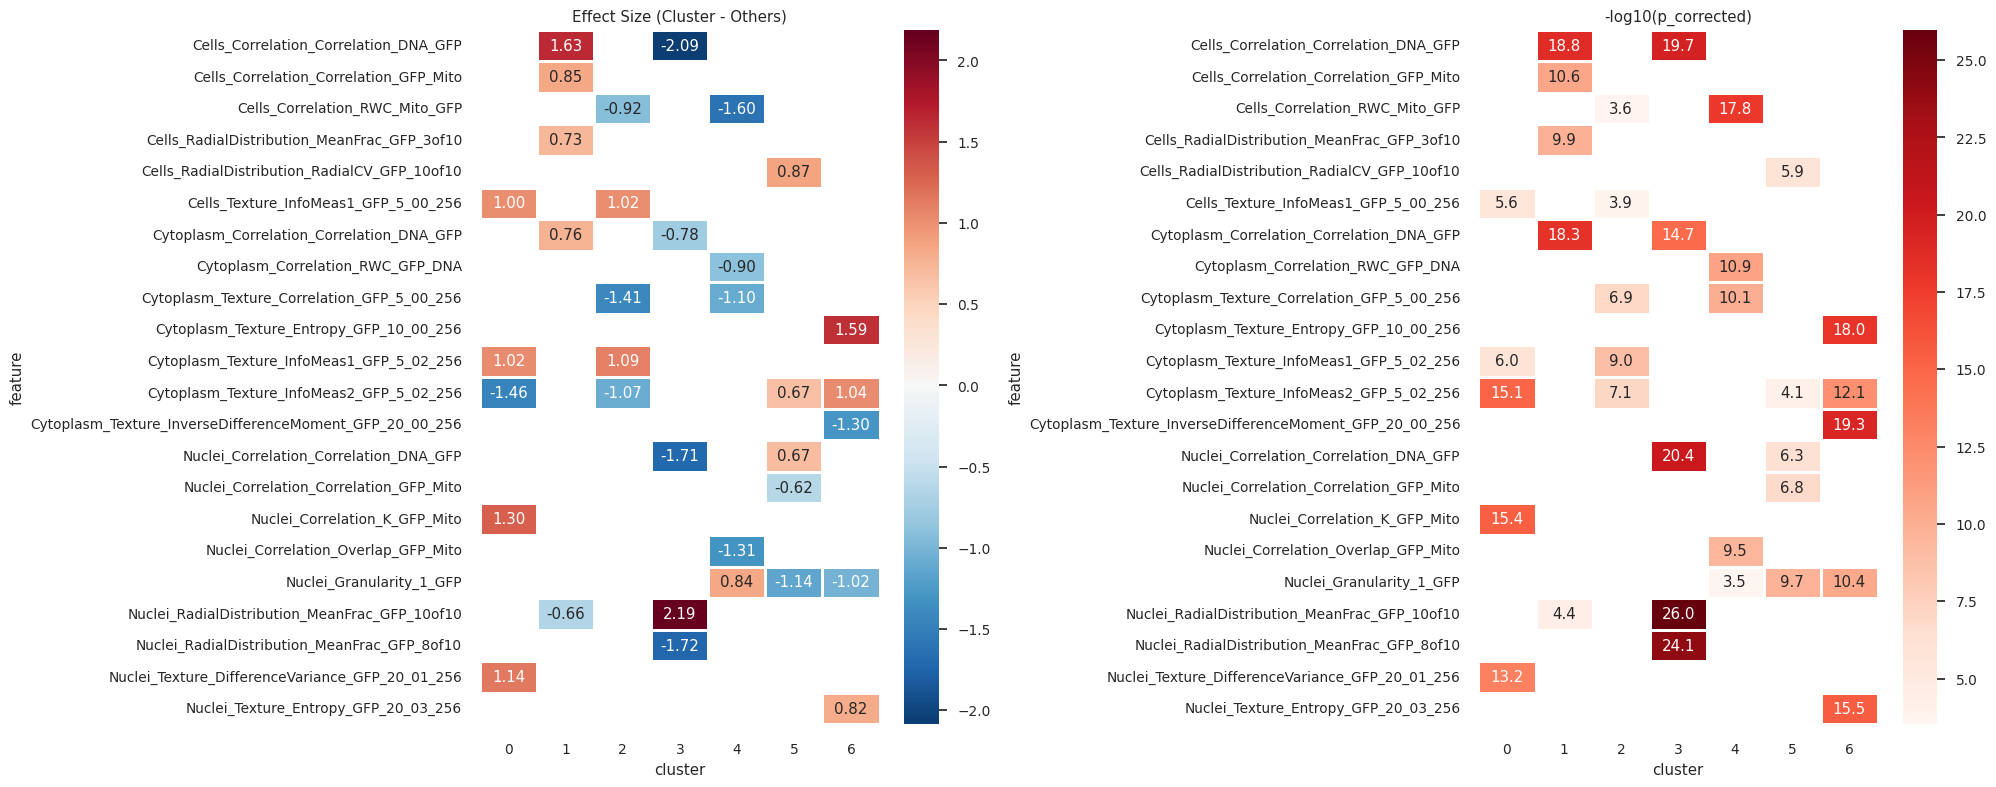

In [316]:
def plot_top_features_heatmap(cluster_results, top_n=5):
    """Plot heatmap of top differential features per cluster"""
    top_features_data = []
    
    for cluster_name, df in cluster_results.items():
        cluster_id = cluster_name.split('_')[1]
        top_features = df.head(top_n)
        
        for _, row in top_features.iterrows():
            top_features_data.append({
                'cluster': cluster_id,
                'feature': row['feature'],
                'effect_size': row['effect_size'],
                'neg_log_p': -np.log10(row['p_corrected'] + 1e-300)
            })
    
    heatmap_df = pd.DataFrame(top_features_data)
    pivot_effect = heatmap_df.pivot(index='feature', columns='cluster', values='effect_size')
    pivot_significance = heatmap_df.pivot(index='feature', columns='cluster', values='neg_log_p')
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    
    sns.heatmap(pivot_effect, annot=True, cmap='RdBu_r', center=0, ax=ax1, fmt='.2f', linewidths=1, square=False)
    ax1.set_title('Effect Size (Cluster - Others)')
    
    sns.heatmap(pivot_significance, annot=True, cmap='Reds', ax=ax2, fmt='.1f', linewidths=1, square=False)
    ax2.set_title('-log10(p_corrected)')

    plt.tight_layout()
    plt.subplots_adjust(wspace=1.)
    plt.show()

sns.set_style(style='white')
plot_top_features_heatmap(cluster_results)

### 2.3 Loading gene location info

In [318]:
gene_loc_df = pl.read_csv("../../3_outputs/agg_gene_normalized_cp_profiles_subloc.csv")
hits_gene_loc_df = gene_loc_df.filter(
    pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["Gene"].unique())
)
hits_gene_w_loc_df = hits_gene_loc_df.filter(
    ~pl.col("Final_Loc").is_in(["Unknown", "Uncertain"])
)
# hits_gene_w_loc_df

# fig, axes = plt.subplots(1,2,figsize=(15,5))
# sns.barplot(
#     data=hits_gene_loc_df.group_by("Main location").agg(pl.len()).sort("len", descending=True),
#     x="len",
#     y="Main location",
#     ax=axes[0]
# )
# sns.barplot(
#     data=hits_gene_loc_df.group_by("Final_Loc").agg(pl.len()).sort("len", descending=True),
#     x="len",
#     y="Final_Loc",
#     ax=axes[1]
# )
# axes[0].set_title(f"Main Location of {hits_gene_loc_df.shape[0]} genes with mislocalized variants")
# axes[1].set_title(f"Approved Location of {hits_gene_loc_df.shape[0]} genes with mislocalized variants")
# axes[0].grid(alpha=.3, axis='x')
# axes[1].grid(alpha=.3, axis='x')
# plt.subplots_adjust(wspace=1)

In Cell Painting assays analyzed with CellProfiler, the feature called Cytoplasm_Granularity refers to the texture of the staining pattern within the cytoplasm, specifically measuring how “grainy” or “speckled” the signal is at different spatial scales.

Here’s a breakdown:

__What it Measures:__

* Granularity is a texture feature that captures the size and frequency of bright spots (or granules) in the image at multiple spatial scales.

* It’s based on morphological operations (often using granulometry) to assess how much image content (signal) is removed by a series of opening operations with structuring elements of increasing sizes.

* High granularity indicates numerous small, bright objects in the cytoplasm (e.g., vesicles, organelles).

* Low granularity implies a more uniform or diffuse staining pattern.

__How It Works in CellProfiler:__

* For each cytoplasm region, CellProfiler computes how much of the signal is lost when applying filters that remove structures below certain sizes.

* The result is a series of granularity features, each corresponding to a different scale (e.g., Cytoplasm_Granularity_1, Cytoplasm_Granularity_2, …).

* These scales correspond to different object sizes: smaller numbers = finer textures; larger numbers = coarser granules.

__In Cell Painting:__

* Different dyes highlight organelles like mitochondria, endoplasmic reticulum, Golgi, etc.

* Cytoplasm_Granularity can reflect changes in organelle morphology or distribution due to chemical or genetic perturbations.

* It’s used as a phenotypic descriptor in high-content screening and profiling.